TASK 1


setup

In [1]:

!pip -q install datasets
import os, json, time, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset

SEED = 42
random.seed(SEED); np.random.seed(SEED)
OUT = "task1_outputs"; os.makedirs(OUT, exist_ok=True)

raw = load_dataset("nyu-mll/glue", "sst2")
X_train, y_train = raw["train"]["sentence"], np.array(raw["train"]["label"])
X_val,   y_val   = raw["validation"]["sentence"], np.array(raw["validation"]["label"])
print(len(X_train), len(X_val), "| train pos rate:", y_train.mean().round(3), "| val pos rate:", y_val.mean().round(3))

README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

sst2/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.11MB            

sst2/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sst2/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 72.8kB            

sst2/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sst2/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  148kB            

sst2/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/67349 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/872 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1821 [00:00<?, ? examples/s]

67349 872 | train pos rate: 0.558 | val pos rate: 0.509


spec model

In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_pipe = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), max_features=20_000)),
    ("clf",   RandomForestClassifier(n_estimators=300, max_depth=30,
                                     min_samples_leaf=5, n_jobs=-1, random_state=SEED)),
])
t0 = time.time(); rf_pipe.fit(X_train, y_train); fit_s = time.time() - t0
print(f"fit time: {fit_s/60:.1f} min")   # expect a few minutes on Colab

rf_val_proba   = rf_pipe.predict_proba(X_val)[:, 1]
rf_val_pred    = (rf_val_proba > 0.5).astype(int)
rf_train_pred  = rf_pipe.predict(X_train)

fit time: 0.4 min


reference rows ( not part of the spec)

In [3]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

maj = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
maj_pred = maj.predict(X_val)

lr_pipe = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), max_features=20_000)),
    ("clf",   LogisticRegression(C=1.0, max_iter=1000)),
]).fit(X_train, y_train)
lr_pred = lr_pipe.predict(X_val)

metrics

In [4]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z*z/n
    c = (p + z*z/(2*n)) / d
    h = z * np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / d
    return c - h, c + h

def summarize(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="binary", zero_division=0)
    lo, hi = wilson(int((y_true == y_pred).sum()), len(y_true))
    return dict(model=name, accuracy=acc, ci_low=lo, ci_high=hi, precision=p, recall=r, f1=f)

rows = [
    summarize("Majority class (ref)",      y_val, maj_pred),
    summarize("LogReg, same TF-IDF (ref)", y_val, lr_pred),
    summarize("Random Forest (SPEC)",      y_val, rf_val_pred),
]
res = pd.DataFrame(rows).round(4)
train_acc = accuracy_score(y_train, rf_train_pred)
print(res.to_string(index=False))
print(f"\nSpec RF train acc: {train_acc:.4f} | val acc: {rows[-1]['accuracy']:.4f}")

res.to_csv(f"{OUT}/task1_results.csv", index=False)
json.dump(dict(seed=SEED, rf_train_acc=train_acc, rf_val_acc=rows[-1]["accuracy"],
               fit_seconds=fit_s, results=rows), open(f"{OUT}/results.json", "w"), indent=2)

                    model  accuracy  ci_low  ci_high  precision  recall     f1
     Majority class (ref)    0.5092  0.4760   0.5422     0.5092  1.0000 0.6748
LogReg, same TF-IDF (ref)    0.8131  0.7858   0.8376     0.7945  0.8536 0.8230
     Random Forest (SPEC)    0.6743  0.6425   0.7046     0.6212  0.9234 0.7428

Spec RF train acc: 0.6806 | val acc: 0.6743


plots

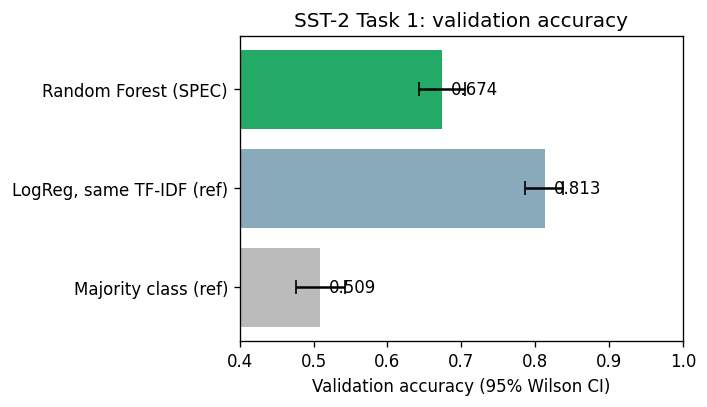

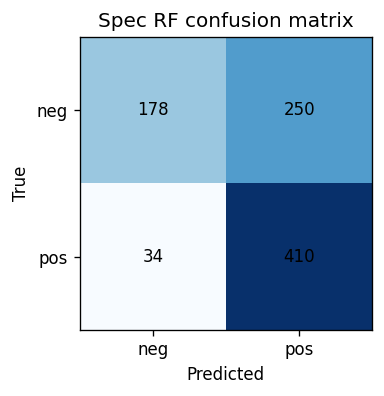

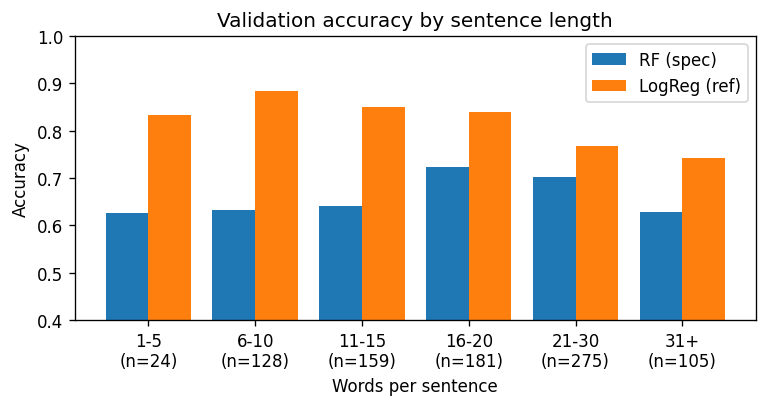

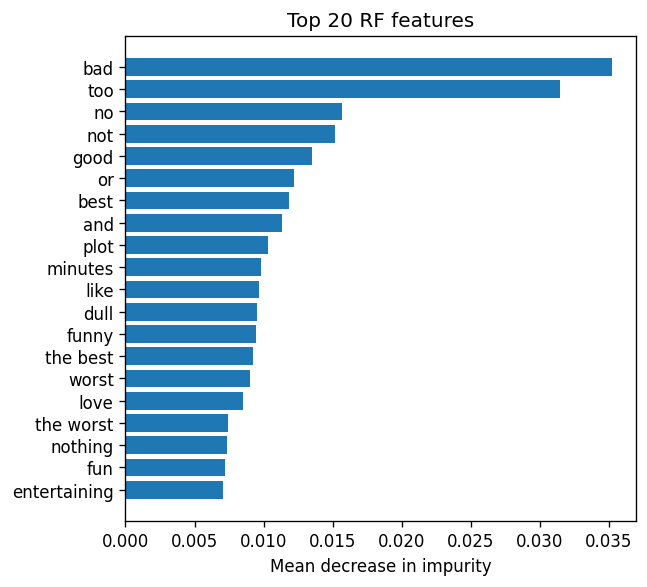

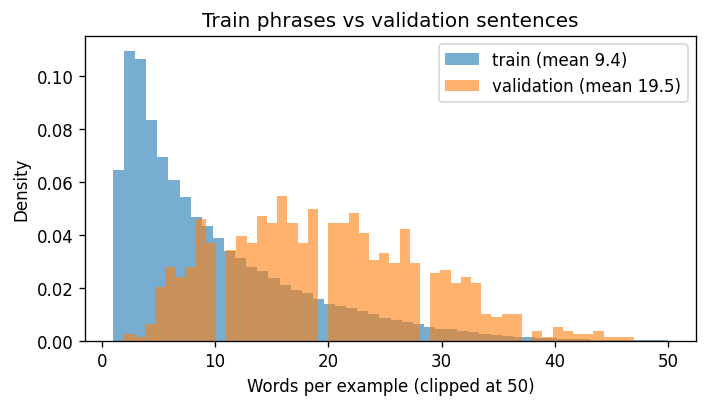

In [5]:
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

# Plot 1: accuracy with 95% CI
fig, ax = plt.subplots(figsize=(6, 3.5))
accs = res["accuracy"].values
err = [accs - res["ci_low"].values, res["ci_high"].values - accs]
ax.barh(res["model"], accs, xerr=err, color=["#bbb", "#8ab", "#2a6"], capsize=4)
ax.set_xlim(0.4, 1.0); ax.set_xlabel("Validation accuracy (95% Wilson CI)")
ax.set_title("SST-2 Task 1: validation accuracy")
for i, a in enumerate(accs): ax.text(a + 0.012, i, f"{a:.3f}", va="center")
plt.tight_layout(); plt.savefig(f"{OUT}/p1_accuracy.png", dpi=200); plt.show()

# Plot 2: confusion matrix (spec RF)
cm = confusion_matrix(y_val, rf_val_pred)
fig, ax = plt.subplots(figsize=(3.8, 3.4))
ax.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm): ax.text(j, i, v, ha="center", va="center")
ax.set_xticks([0, 1], ["neg", "pos"]); ax.set_yticks([0, 1], ["neg", "pos"])
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Spec RF confusion matrix")
plt.tight_layout(); plt.savefig(f"{OUT}/p2_confusion.png", dpi=200); plt.show()

# Plot 3: accuracy by sentence length (val)
lens = np.array([len(s.split()) for s in X_val])
bins = [0, 5, 10, 15, 20, 30, 100]
labels = ["1-5", "6-10", "11-15", "16-20", "21-30", "31+"]
b = pd.cut(lens, bins=bins, labels=labels)
df = pd.DataFrame(dict(bin=b, rf=(rf_val_pred == y_val), lr=(lr_pred == y_val)))
g = df.groupby("bin", observed=True).agg(rf=("rf", "mean"), lr=("lr", "mean"), n=("rf", "size"))
fig, ax = plt.subplots(figsize=(6.5, 3.5))
x = np.arange(len(g)); ax.bar(x - .2, g["rf"], .4, label="RF (spec)"); ax.bar(x + .2, g["lr"], .4, label="LogReg (ref)")
ax.set_xticks(x, [f"{i}\n(n={n})" for i, n in zip(g.index, g["n"])])
ax.set_ylim(0.4, 1); ax.set_ylabel("Accuracy"); ax.set_xlabel("Words per sentence"); ax.legend()
ax.set_title("Validation accuracy by sentence length")
plt.tight_layout(); plt.savefig(f"{OUT}/p3_by_length.png", dpi=200); plt.show()

# Plot 4: top RF feature importances
names = rf_pipe["tfidf"].get_feature_names_out()
imp = rf_pipe["clf"].feature_importances_
top = np.argsort(imp)[-20:]
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.barh(names[top], imp[top]); ax.set_xlabel("Mean decrease in impurity")
ax.set_title("Top 20 RF features")
plt.tight_layout(); plt.savefig(f"{OUT}/p4_importances.png", dpi=200); plt.show()

# Plot 5: train vs validation length distribution (phrase vs sentence shift)
tr_lens = np.array([len(s.split()) for s in X_train])
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(np.clip(tr_lens, 0, 50), bins=50, alpha=.6, density=True, label=f"train (mean {tr_lens.mean():.1f})")
ax.hist(np.clip(lens, 0, 50), bins=50, alpha=.6, density=True, label=f"validation (mean {lens.mean():.1f})")
ax.set_xlabel("Words per example (clipped at 50)"); ax.set_ylabel("Density"); ax.legend()
ax.set_title("Train phrases vs validation sentences")
plt.tight_layout(); plt.savefig(f"{OUT}/p5_length_shift.png", dpi=200); plt.show()

qualitative errors

In [6]:
err_idx = np.where(rf_val_pred != y_val)[0]
conf = np.abs(rf_val_proba[err_idx] - 0.5)
for i in err_idx[np.argsort(-conf)][:8]:   # most confident mistakes
    print(f"true={y_val[i]} pred={rf_val_pred[i]} p(pos)={rf_val_proba[i]:.2f} | {X_val[i]}")

true=0 pred=1 p(pos)=0.65 | in the end , the movie collapses on its shaky foundation despite the best efforts of director joe carnahan . 
true=0 pred=1 p(pos)=0.65 | despite the evocative aesthetics evincing the hollow state of modern love life , the film never percolates beyond a monotonous whine . 
true=0 pred=1 p(pos)=0.65 | the best that can be said about the work here of scottish director ritchie ... is that he obviously does n't have his heart in it . 
true=0 pred=1 p(pos)=0.64 | determined to be fun , and bouncy , with energetic musicals , the humor did n't quite engage this adult . 
true=0 pred=1 p(pos)=0.63 | a disappointment for those who love alternate versions of the bard , particularly ones that involve deep fryers and hamburgers . 
true=0 pred=1 p(pos)=0.63 | sticky sweet sentimentality , clumsy plotting and a rosily myopic view of life in the wwii-era mississippi delta undermine this adaptation . 
true=0 pred=1 p(pos)=0.62 | outer-space buffs might love this film , but o

oof probabilities for task 3

In [7]:
RUN_OOF = False
if RUN_OOF:
    from sklearn.model_selection import StratifiedKFold, cross_val_predict
    from sklearn.base import clone
    cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
    oof = cross_val_predict(clone(rf_pipe), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    np.save(f"{OUT}/rf_oof_train.npy", oof)
np.save(f"{OUT}/rf_val_proba.npy", rf_val_proba)

checking the underfitting claim

TASK 2

In [8]:
# Official LoRA library (microsoft/LoRA, package "loralib" 0.1.2), fetched automatically
!pip -q install transformers datasets
!pip -q install git+https://github.com/microsoft/LoRA.git || pip -q install loralib==0.1.2
import loralib as lora
print("loralib from:", lora.__file__)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
loralib from: /usr/local/lib/python3.13/dist-packages/loralib/__init__.py


setup and data

In [9]:
import os, json, time, random
import numpy as np, pandas as pd, torch, torch.nn as nn
import matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          DataCollatorWithPadding, get_linear_schedule_with_warmup)

SEED = 42
OUT = "task2_outputs"; os.makedirs(OUT, exist_ok=True)
dev = "cuda"
CKPT = "bert-base-uncased"

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

raw = load_dataset("nyu-mll/glue", "sst2")
tok = AutoTokenizer.from_pretrained(CKPT)
def enc(b): return tok(b["sentence"], truncation=True, max_length=128)
ds = raw.map(enc, batched=True, remove_columns=["sentence", "idx"]).rename_column("label", "labels")
coll = DataCollatorWithPadding(tok)
val_labels = np.array(raw["validation"]["label"])
print(len(ds["train"]), len(ds["validation"]))

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/67349 [00:00<?, ? examples/s]

Map:   0%|          | 0/872 [00:00<?, ? examples/s]

Map:   0%|          | 0/1821 [00:00<?, ? examples/s]

67349 872


In [10]:
import torch, subprocess
print("torch:", torch.__version__, "| built for CUDA:", torch.version.cuda, "| available:", torch.cuda.is_available())
print(subprocess.run("nvidia-smi -L; pip list 2>/dev/null | grep -iE '^torch'", shell=True, capture_output=True, text=True).stdout)

torch: 2.11.0+cu130 | built for CUDA: 13.0 | available: True
GPU 0: Tesla T4 (UUID: GPU-41bc0a12-8f72-c193-8cf5-9cc272b9d559)
torch                                 2.11.0+cu130
torchao                               0.10.0
torchaudio                            2.11.0+cu130
torchcodec                            0.11.0+cu130
torchdata                             0.11.0
torchsummary                          1.5.1
torchtune                             0.6.1
torchvision                           0.26.0+cu130



apply official LoRA to BERT

In [11]:
def add_lora(model, r, alpha, dropout=0.1):
    """Replace query/value of every layer with loralib.Linear (same as the repo's RoBERTa code)."""
    for layer in model.bert.encoder.layer:
        att = layer.attention.self
        for nm in ("query", "value"):
            old = getattr(att, nm)
            new = lora.Linear(old.in_features, old.out_features,
                              r=r, lora_alpha=alpha, lora_dropout=dropout)
            new.weight.data.copy_(old.weight.data)    # keep pretrained weights
            new.bias.data.copy_(old.bias.data)
            setattr(att, nm, new)
    lora.mark_only_lora_as_trainable(model)            # freezes everything without 'lora_' in its name
    for p in model.classifier.parameters():            # new head must train (as in run_glue.py)
        p.requires_grad = True
    return model

def count_params(model):
    tr = sum(p.numel() for p in model.parameters() if p.requires_grad)
    head = sum(p.numel() for p in model.classifier.parameters())
    return tr, head

# --- sanity checks ---
set_seed()
m = AutoModelForSequenceClassification.from_pretrained(CKPT, num_labels=2).to(dev).eval()
x = coll([ds["validation"][i] for i in range(4)]); x = {k: v.to(dev) for k, v in x.items() if k != "labels"}
with torch.no_grad(): before = m(**x).logits
add_lora(m, r=8, alpha=16); m.to(dev).eval()
with torch.no_grad(): after = m(**x).logits
print("zero-init check (should be ~0):", (before - after).abs().max().item())
tr, head = count_params(m)
print(f"r=8 trainable: {tr:,} (LoRA {tr-head:,} + head {head:,}); expected LoRA = {24*2*768*8:,}")
print("frozen check, a base weight requires_grad:", m.bert.encoder.layer[0].attention.self.query.weight.requires_grad)
del m

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


zero-init check (should be ~0): 0.0
r=8 trainable: 296,450 (LoRA 294,912 + head 1,538); expected LoRA = 294,912
frozen check, a base weight requires_grad: False


train and eval loop

In [12]:
from torch.utils.data import DataLoader

def evaluate(model):
    model.eval(); out = []                       # loralib merges BA into W here
    dl = DataLoader(ds["validation"], batch_size=128, collate_fn=coll)
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
        for b in dl:
            b = {k: v.to(dev) for k, v in b.items() if k != "labels"}
            out.append(model(**b).logits.float().cpu())
    logits = torch.cat(out).numpy()
    return (logits.argmax(1) == val_labels).mean(), logits

def run(name, r=None, lr=3e-4, epochs=3, bs=16, wd=0.01):
    path = f"{OUT}/{name}.json"
    if os.path.exists(path): return json.load(open(path))      # resume after a Colab disconnect
    set_seed()
    model = AutoModelForSequenceClassification.from_pretrained(CKPT, num_labels=2)
    if r is not None: add_lora(model, r=r, alpha=2*r, dropout=0.1)
    model.to(dev)
    tr, head = count_params(model)
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=wd)
    g = torch.Generator().manual_seed(SEED)
    dl = DataLoader(ds["train"], batch_size=bs, shuffle=True, collate_fn=coll, generator=g)
    total = epochs * len(dl)
    sched = get_linear_schedule_with_warmup(opt, int(0.06 * total), total)
    scaler = torch.amp.GradScaler("cuda")
    log, t0 = [], time.time()
    for ep in range(epochs):
        model.train(); run_loss = 0                             # loralib unmerges here
        for b in dl:
            b = {k: v.to(dev) for k, v in b.items()}
            with torch.autocast("cuda", dtype=torch.float16):
                loss = model(**b).loss
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            run_loss += loss.item()
        acc, logits = evaluate(model)
        log.append(dict(epoch=ep+1, train_loss=run_loss/len(dl), val_acc=float(acc)))
        print(f"{name} ep{ep+1} loss={log[-1]['train_loss']:.4f} val_acc={acc:.4f} ({(time.time()-t0)/60:.1f} min)")
    np.save(f"{OUT}/{name}_val_logits.npy", logits)             # final-epoch logits (for Task 3)
    if r is not None:                                           # small adapter checkpoint (official helper)
        sd = lora.lora_state_dict(model); sd.update({f"classifier.{k}": v for k, v in model.classifier.state_dict().items()})
        torch.save(sd, f"{OUT}/{name}_adapter.pt")
    res = dict(name=name, r=r, lr=lr, trainable_total=tr, trainable_lora_only=tr-head if r else None,
               final_val_acc=float(acc), epochs_log=log, minutes=(time.time()-t0)/60)
    json.dump(res, open(path, "w"), indent=2)
    del model, opt; torch.cuda.empty_cache()
    return res

sweep and full fine-tuning reference

In [13]:
results = []
for r in [4, 8, 16, 32]:
    results.append(run(f"lora_r{r}", r=r, lr=3e-4, epochs=3))
results.append(run("full_ft", r=None, lr=2e-5, epochs=3))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


lora_r4 ep1 loss=0.2861 val_acc=0.9025 (4.3 min)
lora_r4 ep2 loss=0.1995 val_acc=0.9048 (8.5 min)
lora_r4 ep3 loss=0.1722 val_acc=0.9094 (13.6 min)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


lora_r8 ep1 loss=0.2779 val_acc=0.9106 (3.5 min)
lora_r8 ep2 loss=0.1861 val_acc=0.9140 (6.9 min)
lora_r8 ep3 loss=0.1547 val_acc=0.9117 (10.4 min)


... (5 outputs left out)

lora_r32 ep1 loss=0.2652 val_acc=0.9243 (3.4 min)
lora_r32 ep2 loss=0.1628 val_acc=0.9197 (6.9 min)
lora_r32 ep3 loss=0.1206 val_acc=0.9186 (10.2 min)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


full_ft ep1 loss=0.2254 val_acc=0.9220 (5.9 min)
full_ft ep2 loss=0.1002 val_acc=0.9278 (11.8 min)
full_ft ep3 loss=0.0532 val_acc=0.9300 (17.7 min)


results table

In [14]:
def wilson(k, n, z=1.96):
    p = k/n; d = 1 + z*z/n; c = (p + z*z/(2*n))/d
    h = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n))/d
    return c-h, c+h

rows = []
for r in results:
    lo, hi = wilson(round(r["final_val_acc"]*872), 872)
    rows.append(dict(model=r["name"], trainable_params=r["trainable_total"],
                     pct_of_full=100*r["trainable_total"]/results[-1]["trainable_total"],
                     val_acc=r["final_val_acc"], ci_low=lo, ci_high=hi, minutes=r["minutes"]))
tab = pd.DataFrame(rows); print(tab.round(4).to_string(index=False))
tab.to_csv(f"{OUT}/task2_results.csv", index=False)

   model  trainable_params  pct_of_full  val_acc  ci_low  ci_high  minutes
 lora_r4            148994       0.1361   0.9094  0.8885   0.9267  13.6394
 lora_r8            296450       0.2708   0.9117  0.8910   0.9288  10.4023
lora_r16            591362       0.5401   0.9140  0.8935   0.9308  10.2754
lora_r32           1181186       1.0789   0.9186  0.8985   0.9349  10.2185
 full_ft         109483778     100.0000   0.9300  0.9112   0.9452  17.6581


plots


/usr/local/lib/python3.13/dist-packages/matplotlib/cbook.py:1709: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)


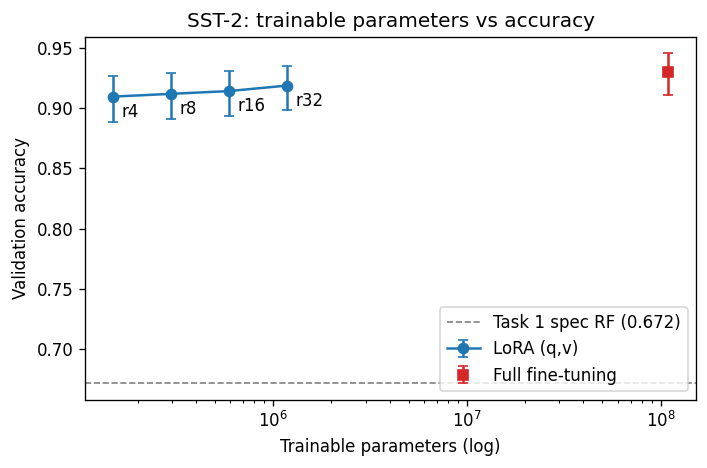

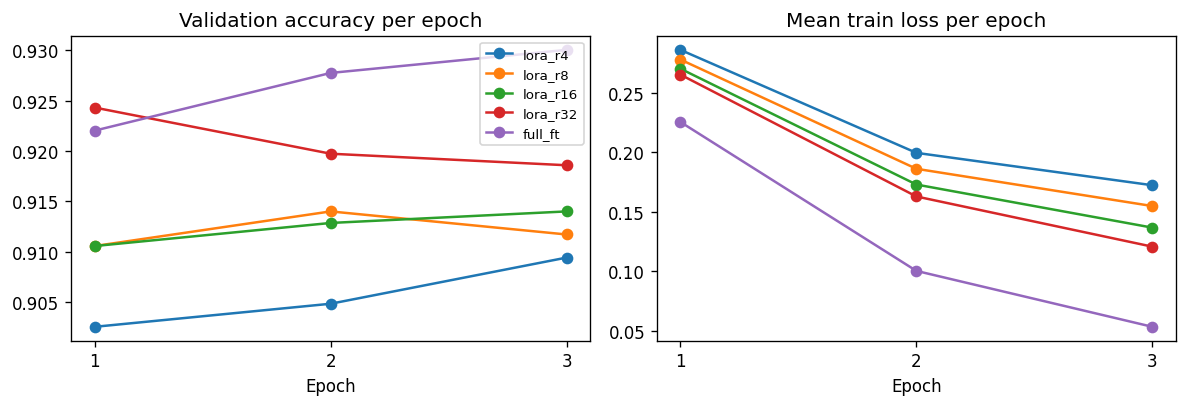

In [15]:
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

# Plot 1: trainable params vs accuracy (required by the spec)
fig, ax = plt.subplots(figsize=(6, 4))
lora_t = tab[tab.model.str.startswith("lora")]; full = tab[tab.model == "full_ft"]
ax.errorbar(lora_t.trainable_params, lora_t.val_acc,
            yerr=[lora_t.val_acc-lora_t.ci_low, lora_t.ci_high-lora_t.val_acc],
            fmt="o-", capsize=3, label="LoRA (q,v)")
for _, row in lora_t.iterrows():
    ax.annotate(row.model.replace("lora_", ""), (row.trainable_params, row.val_acc),
                textcoords="offset points", xytext=(5, -12))
ax.errorbar(full.trainable_params, full.val_acc,
            yerr=[full.val_acc-full.ci_low, full.ci_high-full.val_acc],
            fmt="s", color="C3", capsize=3, label="Full fine-tuning")
ax.axhline(0.672, ls="--", c="gray", lw=1, label="Task 1 spec RF (0.672)")
ax.set_xscale("log"); ax.set_xlabel("Trainable parameters (log)"); ax.set_ylabel("Validation accuracy")
ax.set_title("SST-2: trainable parameters vs accuracy"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(f"{OUT}/t2_params_vs_acc.png", dpi=200); plt.show()

# Plot 2: per-epoch validation accuracy and training loss
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
for r in results:
    e = [l["epoch"] for l in r["epochs_log"]]
    axs[0].plot(e, [l["val_acc"] for l in r["epochs_log"]], "o-", label=r["name"])
    axs[1].plot(e, [l["train_loss"] for l in r["epochs_log"]], "o-", label=r["name"])
axs[0].set_title("Validation accuracy per epoch"); axs[1].set_title("Mean train loss per epoch")
for a in axs: a.set_xlabel("Epoch"); a.set_xticks([1, 2, 3])
axs[0].legend(fontsize=8); plt.tight_layout(); plt.savefig(f"{OUT}/t2_epochs.png", dpi=200); plt.show()

qualitative errors

In [16]:
best = max([r for r in results if r["r"]], key=lambda r: r["final_val_acc"])
lg = np.load(f"{OUT}/{best['name']}_val_logits.npy")
p = torch.softmax(torch.tensor(lg), 1)[:, 1].numpy(); pred = (p > .5).astype(int)
sents = raw["validation"]["sentence"]
wrong = np.where(pred != val_labels)[0]
print("best LoRA:", best["name"], "| errors:", len(wrong))
for i in wrong[np.argsort(-np.abs(p[wrong]-.5))][:8]:
    print(f"true={val_labels[i]} pred={pred[i]} p(pos)={p[i]:.2f} | {sents[i]}")

best LoRA: lora_r32 | errors: 71
true=0 pred=1 p(pos)=1.00 | this riveting world war ii moral suspense story deals with the shadow side of american culture : racial prejudice in its ugly and diverse forms . 
true=0 pred=1 p(pos)=1.00 | moretti 's compelling anatomy of grief and the difficult process of adapting to loss . 
true=0 pred=1 p(pos)=1.00 | the lower your expectations , the more you 'll enjoy it . 
true=1 pred=0 p(pos)=0.00 | hilariously inept and ridiculous . 
true=1 pred=0 p(pos)=0.00 | while there 's something intrinsically funny about sir anthony hopkins saying ` get in the car , bitch , ' this jerry bruckheimer production has little else to offer 
true=0 pred=1 p(pos)=1.00 | it 's everything you do n't go to the movies for . 
true=0 pred=1 p(pos)=1.00 | it 's somewhat clumsy and too lethargically paced -- but its story about a mysterious creature with psychic abilities offers a solid build-up , a terrific climax , and some nice chills along the way . 
true=1 pred=0 p(pos)

freeze the environment

In [17]:
!pip freeze | grep -iE "^(torch|transformers|datasets|numpy|pandas|matplotlib|loralib)==" > task2_outputs/requirements_task2.txt
!cat task2_outputs/requirements_task2.txt

datasets==4.8.5
matplotlib==3.10.0
numpy==2.4.6
pandas==2.2.3
torch==2.11.0+cu130
transformers==5.22.0


TASK 3

In [18]:
!pip -q install datasets scikit-learn scipy
import os, glob, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from datasets import load_dataset
from scipy.special import logit
from scipy.stats import binomtest
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_predict

SEED = 42
OUT = "task3_outputs"; os.makedirs(OUT, exist_ok=True)
T1, T2 = "task1_outputs", "task2_outputs"

raw = load_dataset("nyu-mll/glue", "sst2")
X_val = raw["validation"]["sentence"]; y_val = np.array(raw["validation"]["label"])

# ---- Task 1: spec RF probability on validation (fit on train only) ----
p1 = f"{T1}/rf_val_proba.npy"
if os.path.exists(p1):
    rf_p = np.load(p1)
else:   # fallback: refit the spec Task 1 model (a few minutes on CPU)
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.pipeline import Pipeline
    rf = Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), max_features=20_000)),
                   ("clf", RandomForestClassifier(n_estimators=300, max_depth=30, min_samples_leaf=5,
                                                   n_jobs=-1, random_state=SEED))])
    rf.fit(raw["train"]["sentence"], np.array(raw["train"]["label"]))
    rf_p = rf.predict_proba(X_val)[:, 1]

# ---- Task 2: saved validation logits for every LoRA rank ----
files = sorted(glob.glob(f"{T2}/lora_r*_val_logits.npy"))
assert files, "No Task 2 logits found. Run Task 2 first and copy task2_outputs/."
lora = {os.path.basename(f).replace("_val_logits.npy", ""): np.load(f) for f in files}
assert len(rf_p) == len(y_val) == len(next(iter(lora.values())))
print("ranks found:", list(lora), "| n =", len(y_val))

ranks found: ['lora_r16', 'lora_r32', 'lora_r4', 'lora_r8'] | n = 872


features , meta-model and cv helper

In [19]:
EPS = 1e-4
f1 = logit(np.clip(rf_p, EPS, 1 - EPS))                       # Task 1 feature
f2 = {k: v[:, 1] - v[:, 0] for k, v in lora.items()}           # Task 2 feature = logit of p(pos)

def make_meta(): return make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=1000))

def meta_cv(F, y, repeats=10, seed=SEED):
    """Repeated 5-fold CV. Scaler and LR are refit inside every training fold; each row is scored
    by a meta-model that never saw it. Returns mean acc, std over repeats, and repeat-0 predictions."""
    accs, first = [], None
    for rep in range(repeats):
        cv = StratifiedKFold(5, shuffle=True, random_state=seed + rep)
        pred = cross_val_predict(make_meta(), F, y, cv=cv)
        accs.append((pred == y).mean())
        if rep == 0: first = pred
    return float(np.mean(accs)), float(np.std(accs, ddof=1)), first

def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z * z / n; c = (p + z * z / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h

def mcnemar(pred_a, pred_b, y):
    ca, cb = pred_a == y, pred_b == y
    a, b = int((ca & ~cb).sum()), int((~ca & cb).sum())
    return a, b, (binomtest(a, a + b, 0.5).pvalue if a + b else 1.0)

main comparision and the controls

In [20]:
t1_pred = (rf_p > 0.5).astype(int)
raw2 = {k: v.argmax(1) for k, v in lora.items()}
best = max(raw2, key=lambda k: (raw2[k] == y_val).mean())     # same "best rank" rule as Task 2
t2_pred = raw2[best]
print("best Task 2 rank:", best)

rows = []
def add(name, acc, std=None, pred=None):
    k = int(round(acc * len(y_val))); lo, hi = wilson(k, len(y_val))
    rows.append(dict(model=name, accuracy=acc, cv_std=std, ci_low=lo, ci_high=hi))

add("Task 1: spec RF (raw, thr 0.5)", (t1_pred == y_val).mean())
add(f"Task 2: LoRA {best} (raw)", (t2_pred == y_val).mean())
a, s, pred_t1c = meta_cv(f1.reshape(-1, 1), y_val);        add("Control: Task 1 recalibrated (meta, 1 feature)", a, s)
a, s, pred_t2c = meta_cv(f2[best].reshape(-1, 1), y_val);  add(f"Control: Task 2 recalibrated (meta, 1 feature)", a, s)
F3 = np.column_stack([f1, f2[best]])
a, s, pred_t3 = meta_cv(F3, y_val);                         add("Task 3: meta-model (Task 1 + Task 2)", a, s)

res = pd.DataFrame(rows); print(res.round(4).to_string(index=False))
res.to_csv(f"{OUT}/task3_results.csv", index=False)

print("\nPaired McNemar on the 872 sentences (repeat-0 CV predictions):")
for nm, other in [("Task 2 raw", t2_pred), ("Task 2 recalibrated", pred_t2c), ("Task 1 raw", t1_pred)]:
    x, y_, p = mcnemar(pred_t3, other, y_val)
    print(f"  Task 3 vs {nm}: only-T3-right={x}, only-other-right={y_}, p={p:.4f}")

best Task 2 rank: lora_r32
                                         model  accuracy  cv_std  ci_low  ci_high
                Task 1: spec RF (raw, thr 0.5)    0.6743     NaN  0.6425   0.7046
                   Task 2: LoRA lora_r32 (raw)    0.9186     NaN  0.8985   0.9349
Control: Task 1 recalibrated (meta, 1 feature)    0.7400  0.0017  0.7095   0.7677
Control: Task 2 recalibrated (meta, 1 feature)    0.9217  0.0018  0.9023   0.9380
          Task 3: meta-model (Task 1 + Task 2)    0.9266  0.0019  0.9074   0.9421

Paired McNemar on the 872 sentences (repeat-0 CV predictions):
  Task 3 vs Task 2 raw: only-T3-right=13, only-other-right=7, p=0.2632
  Task 3 vs Task 2 recalibrated: only-T3-right=8, only-other-right=3, p=0.2266
  Task 3 vs Task 1 raw: only-T3-right=250, only-other-right=31, p=0.0000


In [21]:
rk = []
for k in lora:
    a, s, _ = meta_cv(np.column_stack([f1, f2[k]]), y_val)
    a2, s2, _ = meta_cv(f2[k].reshape(-1, 1), y_val)
    rk.append(dict(rank=k, task2_raw=(raw2[k] == y_val).mean(), task2_recal=a2, task3=a, gain_vs_recal=a - a2))
rk = pd.DataFrame(rk); print(rk.round(4).to_string(index=False)); rk.to_csv(f"{OUT}/task3_by_rank.csv", index=False)

    rank  task2_raw  task2_recal  task3  gain_vs_recal
lora_r16     0.9140       0.9172 0.9161        -0.0011
lora_r32     0.9186       0.9217 0.9266         0.0049
 lora_r4     0.9094       0.9155 0.9212         0.0057
 lora_r8     0.9117       0.9124 0.9194         0.0070


In [22]:
c1, c2, c3 = t1_pred == y_val, t2_pred == y_val, pred_t3 == y_val
cats = {"both right": c1 & c2, "only Task 1 right": c1 & ~c2, "only Task 2 right": ~c1 & c2, "both wrong": ~c1 & ~c2}
print(pd.DataFrame([dict(group=k, n=int(m.sum()), task3_acc=float(c3[m].mean()) if m.any() else np.nan)
                    for k, m in cats.items()]).round(3).to_string(index=False))
print(f"oracle (pick the right base model per sentence): {(c1 | c2).mean():.4f}")

fixed  = np.where(~c2 & c3)[0]; broken = np.where(c2 & ~c3)[0]
print(f"\nTask 3 fixes {len(fixed)} Task-2 errors and breaks {len(broken)} Task-2 successes")
for tag, idx in [("FIXED", fixed), ("BROKEN", broken)]:
    for i in idx[:5]:
        print(f"[{tag}] true={y_val[i]} rf_p={rf_p[i]:.2f} bert_p={1/(1+np.exp(-f2[best][i])):.2f} | {X_val[i]}")

            group   n  task3_acc
       both right 554      0.996
only Task 1 right  34      0.147
only Task 2 right 247      0.980
       both wrong  37      0.216
oracle (pick the right base model per sentence): 0.9576

Task 3 fixes 13 Task-2 errors and breaks 7 Task-2 successes
[FIXED] true=0 rf_p=0.50 bert_p=0.57 | a synthesis of cliches and absurdities that seems positively decadent in its cinematic flash and emptiness . 
[FIXED] true=0 rf_p=0.54 bert_p=0.61 | this one is definitely one to skip , even for horror movie fanatics . 
[FIXED] true=0 rf_p=0.46 bert_p=0.85 | the talented and clever robert rodriguez perhaps put a little too much heart into his first film and did n't reserve enough for his second . 
[FIXED] true=0 rf_p=0.52 bert_p=0.59 | this time mr. burns is trying something in the martin scorsese street-realist mode , but his self-regarding sentimentality trips him up again . 
[FIXED] true=0 rf_p=0.51 bert_p=0.56 | nothing is sacred in this gut-buster . 
[BROKEN] true=1

coefficients and plots

standardized coefs [Task1 logit, Task2 logit]: [0.611 3.155]
raw-scale coefs: [2.309 0.548] | intercept: -0.79


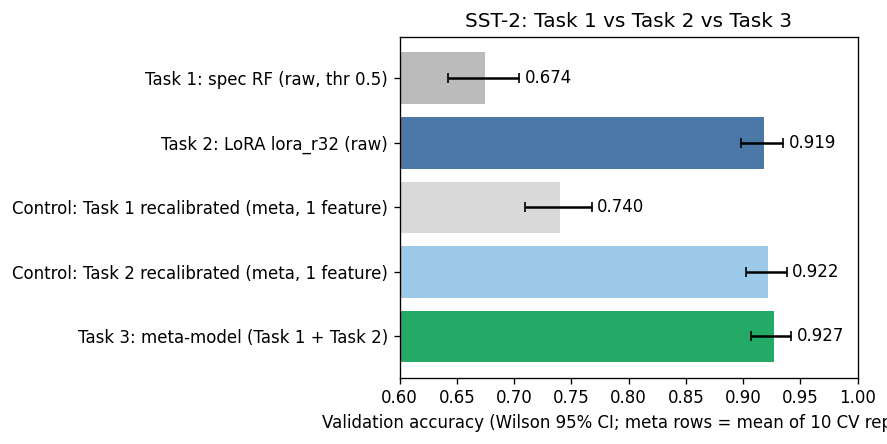

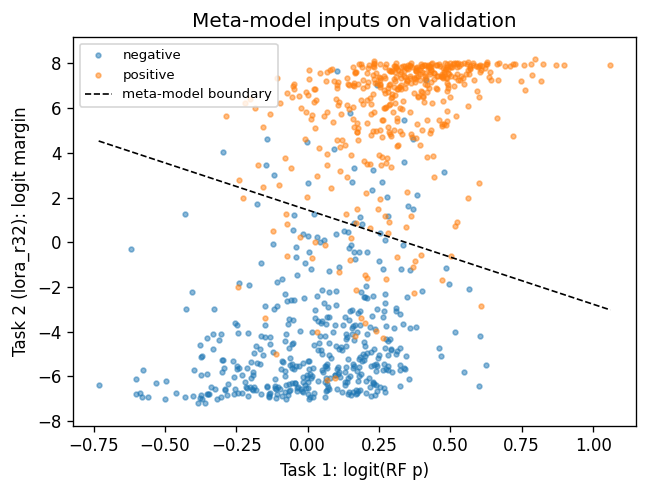

In [23]:
m = make_meta().fit(F3, y_val); sc, lr = m[0], m[1]
w_std = lr.coef_[0]; w_raw = w_std / sc.scale_
print("standardized coefs [Task1 logit, Task2 logit]:", w_std.round(3))
print("raw-scale coefs:", w_raw.round(3), "| intercept:", round(float(lr.intercept_[0] - (w_std * sc.mean_ / sc.scale_).sum()), 3))

plt.rcParams.update({"figure.dpi": 120, "font.size": 10})
# Plot 1: Task 1 vs Task 2 vs Task 3 (+ controls)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
acc = res["accuracy"].values; err = [acc - res["ci_low"].values, res["ci_high"].values - acc]
cols = ["#bbb", "#4c78a8", "#d9d9d9", "#9ecae9", "#2a6"]
ax.barh(res["model"], acc, xerr=err, color=cols, capsize=3); ax.invert_yaxis()
ax.set_xlim(0.6, 1.0); ax.set_xlabel("Validation accuracy (Wilson 95% CI; meta rows = mean of 10 CV repeats)")
for i, (a_, h) in enumerate(zip(acc, res["ci_high"].values)): ax.text(h + 0.005, i, f"{a_:.3f}", va="center")
ax.set_title("SST-2: Task 1 vs Task 2 vs Task 3"); plt.tight_layout()
plt.savefig(f"{OUT}/t3_comparison.png", dpi=200); plt.show()

# Plot 2: feature space with the (descriptive) decision boundary
fig, ax = plt.subplots(figsize=(5.5, 4.2))
ax.scatter(f1[y_val == 0], f2[best][y_val == 0], s=8, alpha=.5, label="negative")
ax.scatter(f1[y_val == 1], f2[best][y_val == 1], s=8, alpha=.5, label="positive")
xs = np.linspace(f1.min(), f1.max(), 50)
if abs(w_raw[1]) > 1e-9:
    b0 = lr.intercept_[0] - (w_std * sc.mean_ / sc.scale_).sum()
    ax.plot(xs, -(w_raw[0] * xs + b0) / w_raw[1], "k--", lw=1, label="meta-model boundary")
ax.set_ylim(f2[best].min() - 1, f2[best].max() + 1)
ax.set_xlabel("Task 1: logit(RF p)"); ax.set_ylabel(f"Task 2 ({best}): logit margin"); ax.legend(fontsize=8)
ax.set_title("Meta-model inputs on validation"); plt.tight_layout()
plt.savefig(f"{OUT}/t3_feature_space.png", dpi=200); plt.show()

json.dump(dict(seed=SEED, best_rank=best, protocol="repeated 5-fold CV of LR meta-model on SST-2 validation (10 repeats)",
               results=res.to_dict("records")), open(f"{OUT}/task3_summary.json", "w"), indent=2)